# ML Assignment 2
# BITS ID : 2026CT05145
# Name : Balaji K

Bank Marketing (term deposit) classification.

Five models: Logistic Regression, Decision Tree, kNN, Naive Bayes, Random Forest.


In [1]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn joblib tabulate

In [2]:
DATA_PATH = "/content/bank-additional-full.csv"
SEP       = ";"
TARGET    = "y"
DROP_COLS = ["duration"]
NA_VALUES = ["unknown"]
SEED      = 42
OUT       = "/content/project-folder"

In [3]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay, f1_score,
                             matthews_corrcoef, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
warnings.filterwarnings("ignore")
os.makedirs(f"{OUT}/model", exist_ok=True)
os.makedirs(f"{OUT}/results", exist_ok=True)

## Step 1 – Load and inspect the data

In [4]:
df = pd.read_csv(DATA_PATH, sep=SEP, na_values=NA_VALUES)
df = df.drop(columns=DROP_COLS)
print("Shape:", df.shape)
df.head()

Shape: (41188, 20)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,NaN,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Missing values per column:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64


     count  share
y                
no   36548  0.887
yes   4640  0.113


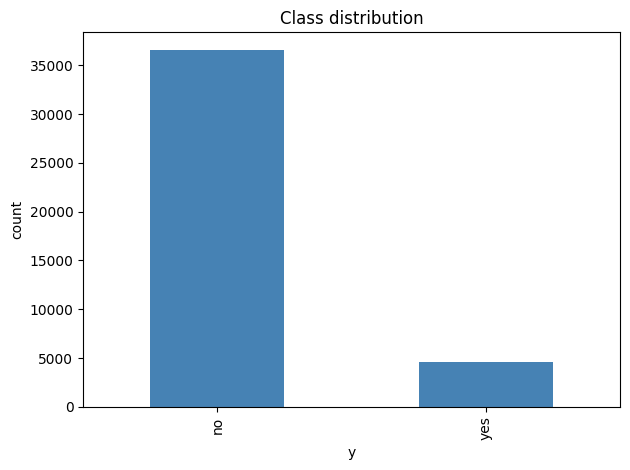

In [6]:
dist = df[TARGET].value_counts()
print(pd.concat([dist, (dist/len(df)).round(3)], axis=1, keys=["count","share"]))
dist.plot(kind="bar", color="steelblue", title="Class distribution")
plt.ylabel("count"); plt.tight_layout()
plt.savefig(f"{OUT}/results/class_distribution.png", dpi=150); plt.show()

## Step 2 – Preprocessing

In [7]:
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", n_dup)

df = df.dropna(subset=[TARGET])
X = df.drop(columns=[TARGET])
le = LabelEncoder()
y = le.fit_transform(df[TARGET])
print("Classes:", dict(zip(le.classes_, le.transform(le.classes_))))

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(len(num_cols), "numeric |", len(cat_cols), "categorical")

# 80:20, stratified, fixed seed
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print("Train:", X_tr.shape, "Test:", X_te.shape)

# save test set (original labels) for the GitHub repo
t = X_te.copy(); t[TARGET] = le.inverse_transform(y_te)
t.to_csv(f"{OUT}/test_data.csv", index=False)

# preprocessing is inside the pipeline -> fitted on TRAIN data only
def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

Duplicates removed: 1784
Classes: {'no': np.int64(0), 'yes': np.int64(1)}
9 numeric | 10 categorical
Train: (31523, 19) Test: (7881, 19)


## Step 3 – Train the five models and compute metrics

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
n_classes = len(le.classes_)
avg = "binary" if n_classes == 2 else "weighted"

rows, preds = [], {}
for name, clf in models.items():
    pipe = Pipeline([("pre", make_pre()), ("clf", clf)])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te); proba = pipe.predict_proba(X_te)
    auc = (roc_auc_score(y_te, proba[:, 1]) if n_classes == 2
           else roc_auc_score(y_te, proba, multi_class="ovr", average="weighted"))
    rows.append({"ML Model Name": name,
                 "Accuracy": accuracy_score(y_te, pred), "AUC": auc,
                 "Precision": precision_score(y_te, pred, average=avg, zero_division=0),
                 "Recall": recall_score(y_te, pred, average=avg, zero_division=0),
                 "F1": f1_score(y_te, pred, average=avg, zero_division=0),
                 "MCC": matthews_corrcoef(y_te, pred)})
    preds[name] = pred
    fname = name.split(" (")[0].lower().replace(" ", "_")
    joblib.dump({"pipeline": pipe, "label_encoder": le}, f"{OUT}/model/{fname}.joblib")
    print("done:", name)

res = pd.DataFrame(rows).set_index("ML Model Name").round(4)
res.to_csv(f"{OUT}/results/metrics.csv")
res

done: Logistic Regression
done: Decision Tree
done: kNN
done: Naive Bayes
done: Random Forest (Ensemble)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9005,0.7991,0.7125,0.2478,0.3677,0.3817
Decision Tree,0.9009,0.7787,0.6635,0.3065,0.4193,0.4066
kNN,0.8906,0.7492,0.5602,0.2935,0.3852,0.3525
Naive Bayes,0.6697,0.7711,0.2224,0.7326,0.3412,0.2601
Random Forest (Ensemble),0.8902,0.7672,0.5540,0.3065,0.3947,0.3578


In [9]:
# markdown table to paste into README.md
print(res.reset_index().to_markdown(index=False))
print("\nBest by MCC:", res["MCC"].idxmax())

| ML Model Name            |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-------------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression      |     0.9005 | 0.7991 |      0.7125 |   0.2478 | 0.3677 | 0.3817 |
| Decision Tree            |     0.9009 | 0.7787 |      0.6635 |   0.3065 | 0.4193 | 0.4066 |
| kNN                      |     0.8906 | 0.7492 |      0.5602 |   0.2935 | 0.3852 | 0.3525 |
| Naive Bayes              |     0.6697 | 0.7711 |      0.2224 |   0.7326 | 0.3412 | 0.2601 |
| Random Forest (Ensemble) |     0.8902 | 0.7672 |      0.554  |   0.3065 | 0.3947 | 0.3578 |

Best by MCC: Decision Tree


## Step 4 – Visualisations

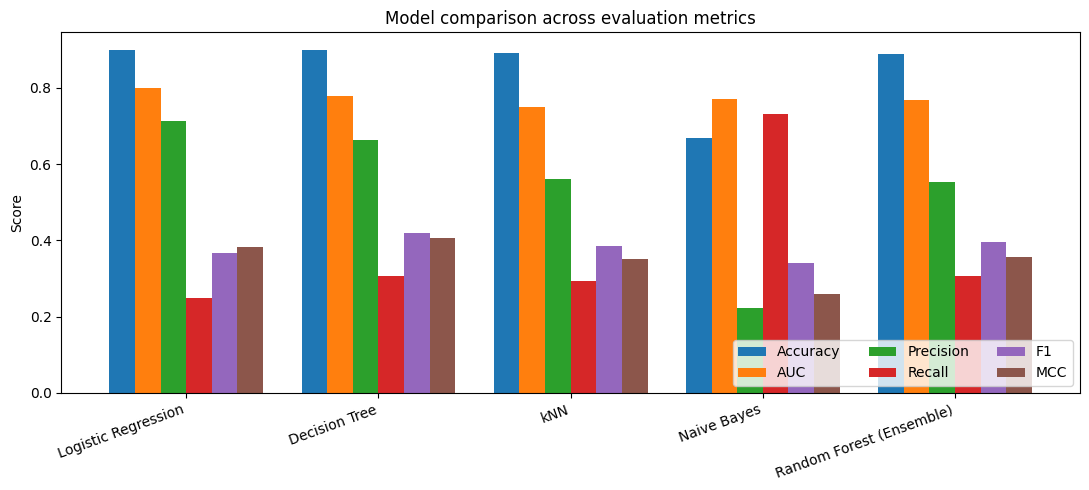

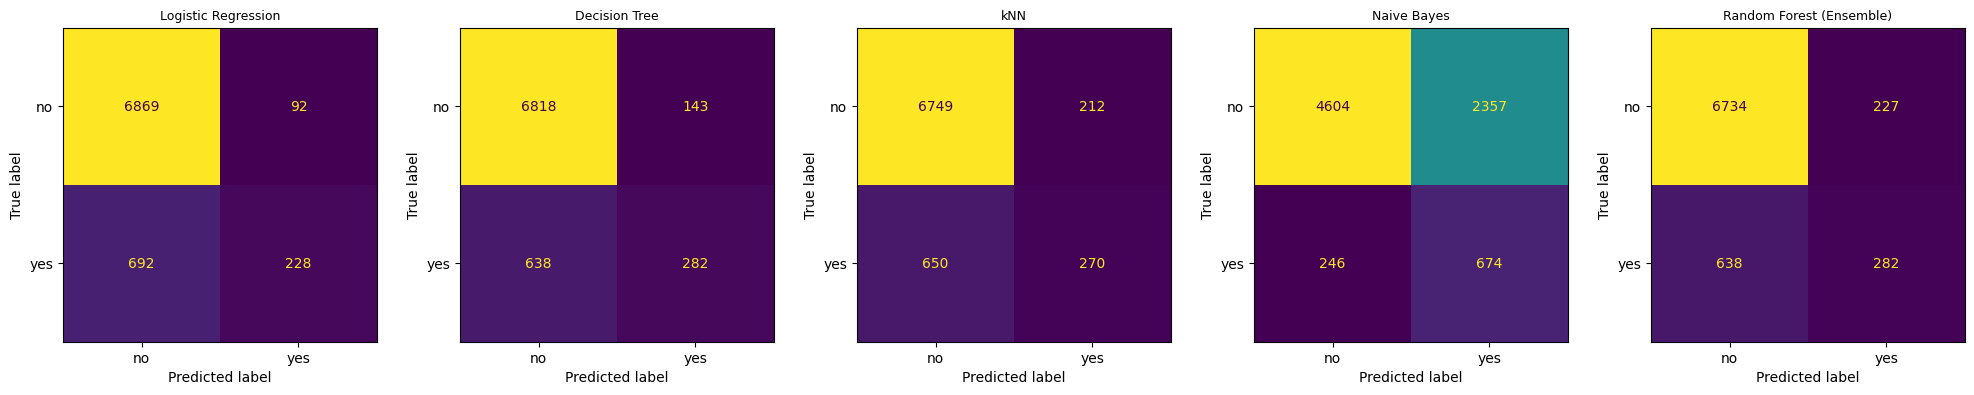

In [10]:
ax = res.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_title("Model comparison across evaluation metrics")
ax.set_ylabel("Score"); ax.set_xlabel(""); ax.legend(loc="lower right", ncol=3)
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT}/results/metrics_comparison.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, p, display_labels=le.classes_, ax=ax, colorbar=False)
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT}/results/confusion_matrices.png", dpi=150); plt.show()

## Step 5 – Download everything (test_data.csv, models, plots)

In [11]:
!cd /content && zip -qr project-folder.zip project-folder
try:
    from google.colab import files
    files.download("/content/project-folder.zip")
except ImportError:
    print("Zip created at /content/project-folder.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>